---
# Imports, function definitions, and file paths

In [1]:
import os
from itertools import combinations
from pathlib import Path
from queue import PriorityQueue

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from loguru import logger
from scipy.spatial.distance import jaccard
from scipy.stats import ttest_ind
from sklearn.cluster import SpectralClustering
from tqdm import tqdm

from philharmonic.utils import (
    hash_cluster,
    load_cluster_json,
    parse_GO_database,
    parse_GO_map,
)

In [2]:
def vst(counts, alpha=1):
    """
    Apply a variance stabilizing transformation to count data.

    Parameters:
    counts (array-like): The input count data
    alpha (float): A small constant to avoid taking log of zero

    Returns:
    numpy.ndarray: The transformed data
    """
    counts = np.asarray(counts)
    return np.log2(counts + np.sqrt(counts + alpha**2))


def bicor_matrix(X, epsilon=1e-12):
    """
    Compute pairwise bi-weight mid-correlation for all genes.

    Parameters:
    X (np.ndarray): A 2D array of shape (n_genes, n_samples) containing normalized count data
    epsilon (float): Small value to avoid division by zero

    Returns:
    np.ndarray: A 2D array of shape (n_genes, n_genes) containing pairwise correlations
    """
    # Compute median and MAD for each gene
    gene_medians = np.median(X, axis=1)
    gene_mads = np.median(np.abs(X - gene_medians[:, np.newaxis]), axis=1)

    # Handle genes with zero MAD
    gene_mads = np.maximum(gene_mads, epsilon)

    # Compute U matrix
    U = (X - gene_medians[:, np.newaxis]) / (9 * gene_mads[:, np.newaxis])

    # Compute weights
    W = (1 - U**2) ** 2
    W[np.abs(U) >= 1] = 0

    # Compute weighted centered expression
    X_weighted = W * (X - gene_medians[:, np.newaxis])

    # Compute pairwise correlations
    norms = np.sqrt(np.sum(X_weighted**2, axis=1))
    norms = np.maximum(norms, epsilon)  # Avoid division by zero
    corr_matrix = np.dot(X_weighted, X_weighted.T) / np.outer(norms, norms)

    # Set diagonal to 1 and handle numerical instability
    np.fill_diagonal(corr_matrix, 1)
    corr_matrix = np.clip(corr_matrix, -1, 1)

    return corr_matrix


def extract_cluster_correlations(
    cluster_members, correlation_df, summary_func=None, dataframe=False
):
    """
    Extract the lower diagonal of pairwise correlations for a set of genes.

    Parameters:
    cluster_members (list): A list of gene names
    correlation_df (pd.DataFrame): A DataFrame containing pairwise correlations

    Returns:
    pd.DataFrame: A DataFrame containing pairwise correlations for the input genes
    """
    members = list(set(cluster_members).intersection(correlation_df.index))
    cluster_correlations = correlation_df.loc[members, members].values[
        np.tril_indices(len(members), k=-1)
    ]
    if summary_func:
        return summary_func(cluster_correlations)
    elif dataframe:
        return correlation_df.loc[members, members]
    else:
        return cluster_correlations


def resample_correlation_matrix(correlation_df, random_seed=42):
    """
    Randomly re-order the row and column names and reassign them to a correlation matrix.
    """
    from copy import deepcopy

    new_df = deepcopy(correlation_df)
    rng = np.random.default_rng(random_seed)
    new_prot_order = rng.permutation(new_df.index)
    new_df.index = new_prot_order
    new_df.columns = new_prot_order
    return new_df


def map_name(pp, name_map):
    pp_id = pp.split(".")[1]
    if pp_id in name_map.index:
        return name_map.loc[pp_id, "gene_ID"]
    else:
        return pp_id


def protein_GO_bit_vector(
    protein_id, go_map, full_go_list, id_col="seq", go_col="GO_ids"
):
    go_bv = np.zeros(len(full_go_list))
    prot_go = go_map.get(protein_id)
    if prot_go is not None:
        for gid in prot_go:
            if gid in full_go_list:
                go_bv[full_go_list.index(gid)] = 1
    return go_bv


def protein_group_bit_vector(protein_id, group_map, full_group_list):
    group_bv = np.zeros(len(full_group_list))
    prot_group = group_map.get(protein_id)
    if prot_group is not None:
        for gid in prot_group:
            if gid in full_group_list:
                group_bv[full_group_list.index(gid)] = 1
    return group_bv

In [3]:
# Initial Files
cluster_file_path = "/mnt/home/ssledzieski/Projects/philharmonic-experiments/results/d_melanogaster/20240913-dmelaAll-phil_v0.2.0/20240912-dmelaAll-phil_v0.2.0_clusters.functional.json"
network_file_path = "/mnt/home/ssledzieski/Projects/philharmonic-experiments/results/d_melanogaster/20240913-dmelaAll-phil_v0.2.0/20240912-dmelaAll-phil_v0.2.0_network.positive.tsv"
go_map_path = "/mnt/home/ssledzieski/Projects/philharmonic-experiments/results/d_melanogaster/20240913-dmelaAll-phil_v0.2.0/20240912-dmelaAll-phil_v0.2.0_GO_map.csv"
cluster_func_path = "/mnt/home/ssledzieski/Projects/philharmonic-experiments/results/d_melanogaster/20240913-dmelaAll-phil_v0.2.0/20240912-dmelaAll-phil_v0.2.0_cluster_graph_functions.tsv"

GO_SLIM_PATH = "/mnt/home/ssledzieski/Projects/philharmonic-experiments/results/p_damicornis/20240917-pdamAll-phil_v0.3.0/goslim_generic.obo"
GO_FULL_PATH = "/mnt/home/ssledzieski/Projects/philharmonic-experiments/results/p_damicornis/20240917-pdamAll-phil_v0.3.0/go.obo"

# Gene Expression Data
data_root = Path(
    "/mnt/home/ssledzieski/database/philharmonic/d_melanogaster/immunity_timeseries/data"
)
metadata_path = data_root / "metadata_table.csv"
raw_count_path = data_root / "raw_counts.csv"
normalized_count_path = data_root / "normalized_counts.csv"
normalized_log_filt_path = data_root / "normalized_counts_log_filt.csv"
immune_genes_path = data_root / "List_of_immune_genes_updated.csv"
name_map_path = data_root / "fbgn_fbtr_fbpp_expanded_fb_2025_02.tsv.gz"

# Output Directories
IMG_DIR = Path(
    "/mnt/home/ssledzieski/Projects/philharmonic-experiments/img/dmel_revisions"
)
os.makedirs(IMG_DIR, exist_ok=True)

---
# Load files

In [4]:
# Load files
cluster_dict = load_cluster_json(cluster_file_path)
go_database = parse_GO_database(GO_FULL_PATH)
go_map = parse_GO_map(go_map_path)
full_G = nx.read_weighted_edgelist(network_file_path, delimiter="\t")

metadata = pd.read_csv(metadata_path, index_col=0).sort_values(by="hours")
expression_df = pd.read_csv(raw_count_path, index_col=0)
normalized_conts = pd.read_csv(normalized_count_path, index_col=0)
normalized_log_filt = pd.read_csv(normalized_log_filt_path, index_col=0)
immune_genes = pd.read_csv(immune_genes_path, index_col=3)

name_map = pd.read_csv(
    name_map_path, sep="\t", compression="gzip", skiprows=4, index_col=9
).dropna()

In [5]:
proteins_in_clusters = []
for clust in tqdm(cluster_dict.values()):
    proteins_in_clusters.extend(clust["members"])
    proteins_in_clusters.extend(list(clust["recipe"]["degree"]["0.75"]))

100%|██████████| 285/285 [00:00<00:00, 886120.56it/s]


In [6]:
flybase_go = pd.read_csv(
    "/mnt/home/ssledzieski/database/flybase/gene_association.fb",
    sep="\t",
    comment="!",
    header=None,
).dropna(subset=[10])
flybase_mapper = (
    pd.read_csv(
        "/mnt/home/ssledzieski/database/flybase/fbgn_fbtr_fbpp_fb_2024_04.tsv",
        sep="\t",
        comment="#",
        header=None,
    )
    .dropna()
    .drop_duplicates(2)
)
flybase_map = dict(zip(flybase_mapper[2], flybase_mapper[0], strict=False))

go_map_fb = {}
for k, v in tqdm(flybase_map.items(), total=len(flybase_map)):
    go_map_fb[f"7227.{k}"] = list(flybase_go[flybase_go[1] == v][4].unique())

go_map_fb = {k: v for k, v in go_map_fb.items() if k in proteins_in_clusters}
logger.info(f"{len(go_map_fb)} proteins mapped with GO terms")

100%|██████████| 30802/30802 [03:04<00:00, 166.95it/s]
2026-03-19 12:57:13.103 | INFO     | __main__:<module>:24 - 4000 proteins mapped with GO terms


---
# Process gene expression data

In [7]:
dense_df = expression_df[
    np.sum(expression_df > 0, axis=1) > expression_df.shape[1] * 0.5
]
vst_df = pd.DataFrame(
    vst(dense_df.values), index=dense_df.index, columns=dense_df.columns
)
dense_corr = bicor_matrix(vst(dense_df.values))
dense_corr_df = pd.DataFrame(dense_corr, index=dense_df.index, columns=dense_df.index)

logger.info(f"Expression data has shape: {expression_df.shape}")
logger.info(f"Dense correlation matrix has shape: {dense_corr_df.shape}")
logger.info(f"Dense correlation matrix has {np.sum(np.isnan(dense_corr))} NaN values")

2026-03-19 12:57:15.015 | INFO     | __main__:<module>:10 - Expression data has shape: (17736, 41)
2026-03-19 12:57:15.017 | INFO     | __main__:<module>:11 - Dense correlation matrix has shape: (15568, 15568)
2026-03-19 12:57:15.321 | INFO     | __main__:<module>:12 - Dense correlation matrix has 0 NaN values


In [8]:
cluster_proteins = set(
    [
        map_name(i, name_map)
        for i in set.union(*[set(i["members"]) for i in cluster_dict.values()])
    ]
)
removed_proteins = set(expression_df.index).difference(dense_corr_df.index)
removed_cluster_proteins = cluster_proteins.intersection(removed_proteins)
logger.info(
    f"Removed {len(removed_proteins)} proteins from the expression data because of sparsity, {len(removed_cluster_proteins)} which were in clusters."
)

2026-03-19 12:57:15.353 | INFO     | __main__:<module>:9 - Removed 2168 proteins from the expression data because of sparsity, 94 which were in clusters.


---
# Compute clusters based on just function

In [9]:
go_assigned = set()
for clust in tqdm(cluster_dict.values()):
    for m in clust["members"]:
        go_assigned.update(go_map.get(m, []))
go_assigned = sorted(list(go_assigned.intersection(go_database.keys())))

logger.info(f"{len(go_assigned)} GO terms assigned")

100%|██████████| 285/285 [00:00<00:00, 19492.17it/s]
2026-03-19 12:57:15.381 | INFO     | __main__:<module>:7 - 10199 GO terms assigned


In [10]:
# Compute GO bit vectors for each protein
protein_GO_bvs = {}
for pid in tqdm(proteins_in_clusters):
    protein_GO_bvs[pid] = protein_GO_bit_vector(pid, go_map, go_assigned)

100%|██████████| 6949/6949 [00:42<00:00, 164.27it/s]


In [11]:
# Compute all jaccard similarities
X = np.array([protein_GO_bvs[pid] for pid in proteins_in_clusters], dtype=np.float32)

intersection = X @ X.T
row_sums = X.sum(axis=1)
union = row_sums[:, None] + row_sums[None, :] - intersection

function_jaccard_similarity = np.divide(intersection, union, where=union > 0)

function_jaccard_df = pd.DataFrame(
    function_jaccard_similarity,
    index=proteins_in_clusters,
    columns=proteins_in_clusters,
)

/tmp/ipykernel_2882014/2618784039.py:8: UserWarning: 'where' used without 'out', expect unitialized memory in output. If this is intentional, use out=None.
  function_jaccard_similarity = np.divide(intersection, union, where=union > 0)


In [12]:
# Initial clustering

init_k = 500
random_seed = 42

SC = SpectralClustering(
    n_clusters=init_k,
    assign_labels="discretize",
    random_state=random_seed,
    affinity="precomputed",
)
SC.fit(function_jaccard_similarity)

/mnt/home/ssledzieski/Projects/philharmonic-experiments/code/.venv/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


,"n_clusters n_clusters: int, default=8The dimension of the projection subspace.",500
,"eigen_solver eigen_solver: {'arpack', 'lobpcg', 'amg'}, default=NoneThe eigenvalue decomposition strategy to use. AMG requires pyamgto be installed. It can be faster on very large, sparse problems,but may also lead to instabilities. If None, then ``'arpack'`` isused. See [4]_ for more details regarding `'lobpcg'`.",None
,"n_components n_components: int, default=NoneNumber of eigenvectors to use for the spectral embedding. If None,defaults to `n_clusters`.",None
,"random_state random_state: int, RandomState instance, default=NoneA pseudo random number generator used for the initializationof the lobpcg eigenvectors decomposition when `eigen_solver =='amg'`, and for the K-Means initialization. Use an int to makethe results deterministic across calls (See:term:`Glossary `)... note:: When using `eigen_solver == 'amg'`, it is necessary to also fix the global numpy seed with `np.random.seed(int)` to get deterministic results. See https://github.com/pyamg/pyamg/issues/139 for further information.",42
,"n_init n_init: int, default=10Number of time the k-means algorithm will be run with differentcentroid seeds. The final results will be the best output of n_initconsecutive runs in terms of inertia. Only used if``assign_labels='kmeans'``.",10
,"gamma gamma: float, default=1.0Kernel coefficient for rbf, poly, sigmoid, laplacian and chi2 kernels.Ignored for ``affinity='nearest_neighbors'``, ``affinity='precomputed'``or ``affinity='precomputed_nearest_neighbors'``.",1.0
,"affinity affinity: str or callable, default='rbf'How to construct the affinity matrix. - 'nearest_neighbors': construct the affinity matrix by computing a graph of nearest neighbors. - 'rbf': construct the affinity matrix using a radial basis function (RBF) kernel. - 'precomputed': interpret ``X`` as a precomputed affinity matrix, where larger values indicate greater similarity between instances. - 'precomputed_nearest_neighbors': interpret ``X`` as a sparse graph of precomputed distances, and construct a binary affinity matrix from the ``n_neighbors`` nearest neighbors of each instance. - one of the kernels supported by :func:`~sklearn.metrics.pairwise.pairwise_kernels`.Only kernels that produce similarity scores (non-negative values thatincrease with similarity) should be used. This property is not checkedby the clustering algorithm.",'precomputed'
,"n_neighbors n_neighbors: int, default=10Number of neighbors to use when constructing the affinity matrix usingthe nearest neighbors method. Ignored for ``affinity='rbf'``.",10
,"eigen_tol eigen_tol: float, default=""auto""Stopping criterion for eigen decomposition of the Laplacian matrix.If `eigen_tol=""auto""` then the passed tolerance will depend on the`eigen_solver`:- If `eigen_solver=""arpack""`, then `eigen_tol=0.0`;- If `eigen_solver=""lobpcg""` or `eigen_solver=""amg""`, then `eigen_tol=None` which configures the underlying `lobpcg` solver to automatically resolve the value according to their heuristics. See, :func:`scipy.sparse.linalg.lobpcg` for details.Note that when using `eigen_solver=""lobpcg""` or `eigen_solver=""amg""`values of `tol<1e-5` may lead to convergence issues and should beavoided... versionadded:: 1.2 Added 'auto' option.",'auto'
,"assign_labels assign_labels: {'kmeans', 'discretize', 'cluster_qr'}, default='kmeans'The strategy for assigning labels in the embedding space. There are twoways to assign labels after the Laplacian embedding. k-means is apopular choice, but it can be sensitive to initialization.Discretization is another approach which is less sensitive to randominitialization [3]_.The cluster_qr method [5]_ directly extract clusters from eigenvectorsin spectral clustering. In contrast to k-means and discretization, cluster_qrhas no tuning parameters and runs no iterations, yet may outperformk-means and discretization in terms of both quality and speed... versionchanged:: 1.1 Added new labeling method 'c

In [13]:
# Recursive clustering of large clusters
min_cluster_size = 3
cluster_divisor = 20


def extract_clusters(
    SC: SpectralClustering, og_clust: list, og_csize: int, verbosity=2
):
    subCs = []
    for label in set(SC.labels_):  # go through all labels
        # make a list of all nodes in the cluster assigned to given label
        subCs.append([og_clust[i] for i in range(og_csize) if SC.labels_[i] == label])

    if verbosity > 0:
        to_print = f"Cluster of size {og_csize} -> split into {len(subCs)} clusters "

        if verbosity > 1:
            to_print += "of sizes: "
            for subC in subCs:
                to_print += f"{len(subC)}/"
        logger.info(to_print[:-1])

    # return list of tuples of priority of cluster and list of nodes in cluster
    return [(1 / len(subC), subC) for subC in subCs]


clusts = [
    [j for j in range(len(SC.labels_)) if SC.labels_[j] == i]
    for i in range(max(SC.labels_) + 1)
    if i in SC.labels_
]
clusts.sort(key=lambda x: len(x), reverse=True)

logger.info(f"Initial Clustering: {len(clusts)} clusters")
clustQ: PriorityQueue[tuple[float, list[int]]] = PriorityQueue()
for c in clusts:
    clustQ.put((1 / len(c), c))

logger.info(f"Splitting large clusters into {cluster_divisor} clusters...")
while True:
    priority, c = clustQ.get()
    csize = int(1 / priority)

    n_clusters = int(
        np.round(csize / cluster_divisor)
    )  # NOTE: this changed so that we are left with clusters of max size 30

    if n_clusters < 2:
        clustQ.put((priority, c))
        break

    SC2 = SpectralClustering(
        n_clusters=n_clusters,
        assign_labels="discretize",
        random_state=random_seed,
        affinity="precomputed",
    )
    SC2.fit(function_jaccard_similarity[c, :][:, c])

    subClusts = extract_clusters(SC2, c, csize, verbosity=2)
    for subClust in subClusts:
        clustQ.put(subClust)

logger.info(f"Removing small clusters (<{min_cluster_size})...")
filtered_clusters = []
while not clustQ.empty():
    _, c = clustQ.get()
    filtered_clusters.append(c)
filtered_clusters = [i for i in filtered_clusters if len(i) >= min_cluster_size]
logger.info(f"Final Clustering: {len(filtered_clusters)} clusters")

2026-03-19 12:58:59.701 | INFO     | __main__:<module>:34 - Initial Clustering: 419 clusters
2026-03-19 12:58:59.703 | INFO     | __main__:<module>:39 - Splitting large clusters into 20 clusters...
2026-03-19 12:58:59.714 | INFO     | __main__:extract_clusters:21 - Cluster of size 213 -> split into 11 clusters of sizes: 34/2/6/38/14/8/13/2/27/53/16
2026-03-19 12:58:59.720 | INFO     | __main__:extract_clusters:21 - Cluster of size 197 -> split into 10 clusters of sizes: 9/3/98/17/10/12/5/5/36/2
2026-03-19 12:58:59.725 | INFO     | __main__:extract_clusters:21 - Cluster of size 196 -> split into 10 clusters of sizes: 125/13/2/4/9/3/5/2/25/8
2026-03-19 12:58:59.730 | INFO     | __main__:extract_clusters:21 - Cluster of size 178 -> split into 9 clusters of sizes: 3/66/1/4/8/2/16/74/4
2026-03-19 12:58:59.734 | INFO     | __main__:extract_clusters:21 - Cluster of size 170 -> split into 8 clusters of sizes: 56/1/3/6/23/33/42/6
2026-03-19 12:58:59.738 | INFO     | __main__:extract_clusters:21

In [14]:
clusters_by_function_names = [
    [proteins_in_clusters[i] for i in cl] for cl in filtered_clusters
]

clusters_by_function = {}
for cl in clusters_by_function_names:
    members = cl
    uqid = str(hash_cluster(cl))
    subgraph = full_G.subgraph(cl)
    clusters_by_function[uqid] = {
        "members": members,
        "graph": [
            (i[0], i[1], subgraph.get_edge_data(i[0], i[1])["weight"])
            for i in subgraph.edges()
        ],
    }
logger.info(f"{len(clusters_by_function)} clusters by function")

2026-03-19 12:59:00.199 | INFO     | __main__:<module>:17 - 594 clusters by function


---
# Compare clusterings based on correlation of expression

In [15]:
dense_corr_df

,FBgn0000003,FBgn0000008,FBgn0000014,FBgn0000015,FBgn0000017,FBgn0000018,FBgn0000024,FBgn0000028,FBgn0000032,FBgn0000036,...,FBgn0285950,FBgn0285951,FBgn0285952,FBgn0285954,FBgn0285955,FBgn0285962,FBgn0285963,FBgn0285970,FBgn0285971,FBgn0285991
FBgn0000003,1.000000,0.627676,0.607658,0.564500,0.593670,0.662889,0.598972,0.599109,0.606533,0.551089,...,0.611660,0.581670,0.581167,0.607410,0.543783,0.710640,0.353477,0.637662,0.696864,0.626177
FBgn0000008,0.627676,1.000000,0.656528,0.745286,0.703889,0.772026,0.725589,0.734952,0.800119,0.758128,...,0.764414,0.805512,0.727280,0.706178,0.641502,0.831836,0.599878,0.800955,0.769260,0.777435
FBgn0000014,0.607658,0.656528,1.000000,0.790280,0.844279,0.874305,0.857175,0.748937,0.905543,0.823806,...,0.740257,0.701394,0.783165,0.857949,0.731458,0.805031,0.635496,0.789388,0.760510,0.899668
FBgn0000015,0.564500,0.745286,0.790280,1.000000,0.807432,0.850285,0.749537,0.824592,0.881673,0.863507,...,0.662290,0.714605,0.630072,0.888444,0.695723,0.798568,0.671996,0.782226,0.813136,0.803093
FBgn0000017,0.593670,0.703889,0.844279,0.807432,1.000000,0.828733,0.770724,0.868583,0.864981,0.858935,...,0.650229,0.654091,0.645470,0.795441,0.840923,0.755657,0.837364,0.721078,0.708921,0.819010
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
FBgn0285962,0.710640,0.831836,0.805031,0.798568,0.755657,0.933959,0.745976,0.822755,0.902524,0.847709,...,0.858617,0.862241,0.860646,0.792421,0.668171,1.000000,0.676520,0.924862,0.825531,0.805919
FBgn0285963,0.353477,0.599878,0.635496,0.671996,0.837364,0.744483,0.643133,0.699179,0.706700,0.737951,...,0.688698,0.617663,0.668380,0.651864,0.855491,0.676520,1.000000,0.653662,0.584277,0.646182
FBgn0285970,0.637662,0.800955,0.789388,0.782226,0.721078,0.911352,0.736671,0.819772,0.903713,0.798818,...,0.873824,0.931367,0.859559,0.828927,0.633453,0.924862,0.653662,1.000000,0.802573,0.800260
FBgn0285971,0.696864,0.769260,0.760510,0.813136,0.708921,0.815350,0.680214,0.698483,0.842882,0.740751,...,0.704641,0.726867,0.683187,0.836365,0.666468,0.825531,0.584277,0.802573,1.000000,0.781425


In [16]:
cluster_correlations = {
    "Philharmonic": [
        extract_cluster_correlations(
            [
                map_name(n, name_map)
                for n in c["members"] + list(c["recipe"]["degree"]["0.75"])
            ],
            dense_corr_df,
            np.median,
        )
        for c in tqdm(cluster_dict.values(), total=len(cluster_dict))
    ],
    "GO_Clusters": [
        extract_cluster_correlations(
            [map_name(n, name_map) for n in c["members"]], dense_corr_df, np.median
        )
        for c in tqdm(clusters_by_function.values(), total=len(clusters_by_function))
    ],
}

 71%|███████   | 201/285 [00:00<00:00, 264.77it/s]/mnt/home/ssledzieski/Projects/philharmonic-experiments/code/.venv/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/mnt/home/ssledzieski/Projects/philharmonic-experiments/code/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
 82%|████████▏ | 234/285 [00:00<00:00, 284.24it/s]/mnt/home/ssledzieski/Projects/philharmonic-experiments/code/.venv/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/mnt/home/ssledzieski/Projects/philharmonic-experiments/code/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
 99%|█████████▊| 281/285 [

In [17]:
plot_df = []
for key, corrs in cluster_correlations.items():
    for corr in corrs:
        plot_df.append(
            {"Median Bi-Weight Mid Correlation": corr, "Expression Data": key}
        )
plot_df = pd.DataFrame(plot_df)
plot_df.head()

,Median Bi-Weight Mid Correlation,Expression Data
0,0.630303,Philharmonic
1,0.484855,Philharmonic
2,0.560482,Philharmonic
3,0.660933,Philharmonic
4,0.705268,Philharmonic


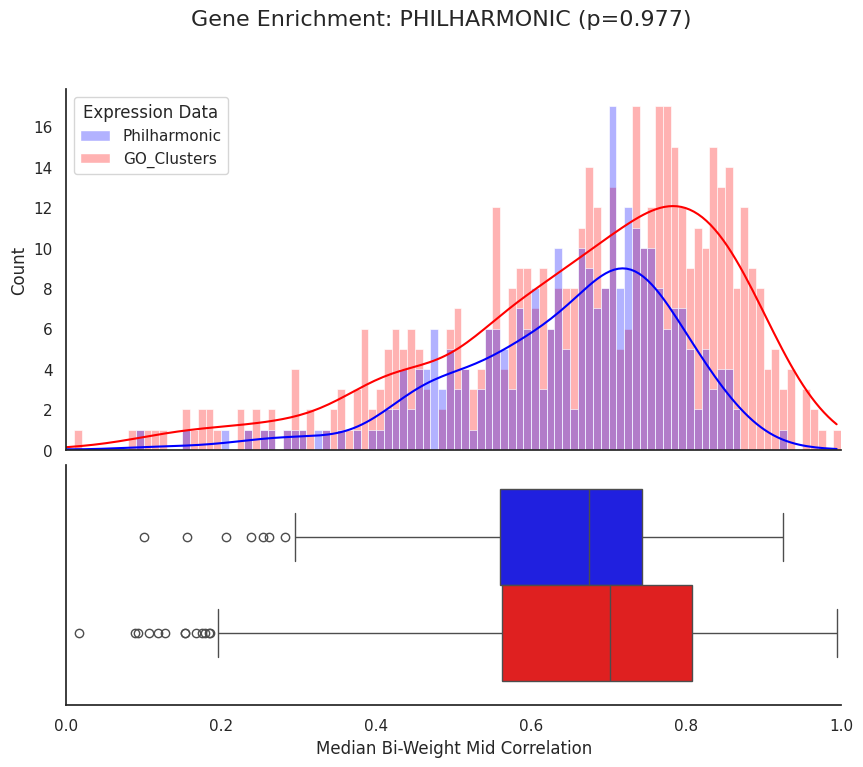

In [18]:
sns.set_palette("colorblind")
sns.set_theme(style="white", palette="pastel", font_scale=1)

phil_correlations = np.array(cluster_correlations["Philharmonic"])
phil_correlations = phil_correlations[~np.isnan(phil_correlations)]

func_correlations = np.array(cluster_correlations["GO_Clusters"])
func_correlations = func_correlations[~np.isnan(func_correlations)]

tstat_rand, p_rand = ttest_ind(
    phil_correlations, func_correlations, alternative="greater"
)

# plot_df = cluster_corr_df.melt("key").rename(
#     {"value": "Median Bi-Weight Mid Correlation", "variable": "Expression Data"}, axis=1
# )

# Create figure and gridspec
fig = plt.figure(figsize=(10, 8))
gs = fig.add_gridspec(2, 1, height_ratios=[3, 2], hspace=0.05)

# Create top subplot for histogram
ax0 = fig.add_subplot(gs[0])
ax1 = fig.add_subplot(gs[1])

sns.histplot(
    data=plot_df,
    x="Median Bi-Weight Mid Correlation",
    hue="Expression Data",
    alpha=0.3,
    kde=True,
    bins=np.arange(-0.1, 1.05, 0.01),
    palette=["blue", "red"],
    common_norm=False,
    ec="white",
    ax=ax0,
)

sns.boxplot(
    data=plot_df,
    x="Median Bi-Weight Mid Correlation",
    hue="Expression Data",
    palette=["blue", "red"],
    ax=ax1,
)

# set xlim 0 to 1
plt.xlim(0, 1)

ax0.set_xlabel("")  # Remove x-label from top plot
ax1.set_xlabel("Median Bi-Weight Mid Correlation")  # Add x-label to bottom plot
ax0.set_xticklabels([])  # Remove x-ticks from top plot


ax0.set_xlim(ax1.get_xlim())  # Align the x-axis of both subplots
ax1.get_legend().remove()  # Remove legend from bottom plot

plt.suptitle(f"Gene Enrichment: PHILHARMONIC (p={p_rand:.3})", fontsize=16)

# Show the plot
sns.despine()
# plt.savefig(IMG_DIR / "gexp_enrichment_combined.svg", bbox_inches="tight", dpi=300)
plt.show()

---
# Compare clusterings based on shared pathways

In [19]:
flybase_group = pd.read_csv(
    "/mnt/home/ssledzieski/database/flybase/gene_group_data_fb_2024_06.tsv",
    sep="\t",
    comment="#",
    header=None,
)
flybase_group.columns = [
    "fbid",
    "fbgrp_symbol",
    "fbgrp_name",
    "parent_fbgrp_id",
    "parent_fbgrp_symbol",
    "group_member_geneid",
    "group_member_symbol",
]
flybase_inv_map = {v: k for k, v in flybase_map.items()}
flybase_group["fbpp"] = flybase_group["group_member_geneid"].map(flybase_inv_map)
flybase_group = flybase_group.dropna(subset=["fbpp"])
pic_strip = [flybase_map.get(i.split(".")[1], None) for i in proteins_in_clusters]
flybase_group = flybase_group[flybase_group["group_member_geneid"].isin(pic_strip)]

group_map = {}
for k, v in tqdm(flybase_map.items(), total=len(flybase_map)):
    group_map[f"7227.{k}"] = list(
        flybase_group[flybase_group["group_member_geneid"] == v][
            "fbgrp_symbol"
        ].unique()
    )

group_map = {k: v for k, v in group_map.items() if k in proteins_in_clusters}
logger.info(f"{len(group_map)} proteins mapped with groups terms")

  0%|          | 0/30802 [00:00<?, ?it/s]

100%|██████████| 30802/30802 [00:09<00:00, 3313.56it/s]
2026-03-19 12:59:13.291 | INFO     | __main__:<module>:31 - 4000 proteins mapped with groups terms


In [20]:
group_assigned = set()
for clust in tqdm(cluster_dict.values()):
    for m in clust["members"] + list(clust["recipe"]["degree"]["0.75"]):
        group_assigned.update(group_map.get(m, []))
group_assigned = sorted(list(group_assigned))

logger.info(f"{len(group_assigned)} groups assigned")

100%|██████████| 285/285 [00:00<00:00, 115495.33it/s]
2026-03-19 12:59:13.303 | INFO     | __main__:<module>:7 - 853 groups assigned


In [21]:
protein_group_bvs = {}
for pid in tqdm(proteins_in_clusters):
    protein_group_bvs[pid] = protein_group_bit_vector(pid, group_map, group_assigned)

100%|██████████| 6949/6949 [00:00<00:00, 125941.31it/s]


In [22]:
phil_cluster_jaccards = {}

for k, clust in tqdm(cluster_dict.items()):
    cjaccard = []
    for p1, p2 in combinations(
        clust["members"] + list(clust["recipe"]["degree"]["0.75"]), 2
    ):
        jc = 1 - jaccard(protein_group_bvs[p1], protein_group_bvs[p2])
        cjaccard.append(jc)
    phil_cluster_jaccards[k] = np.array(cjaccard)

100%|██████████| 285/285 [00:00<00:00, 377.59it/s]


In [23]:
go_cluster_jaccards = {}

for k, clust in tqdm(clusters_by_function.items()):
    cjaccard = []
    for p1, p2 in combinations(clust["members"], 2):
        jc = 1 - jaccard(protein_group_bvs[p1], protein_group_bvs[p2])
        cjaccard.append(jc)
    go_cluster_jaccards[k] = np.array(cjaccard)

100%|██████████| 594/594 [00:00<00:00, 1590.52it/s]


In [24]:
phil_mean = [np.mean(i) for i in phil_cluster_jaccards.values()]
go_mean = [np.mean(i) for i in go_cluster_jaccards.values()]
tstat_rand, p_rand = ttest_ind(phil_mean, go_mean, alternative="greater")
print(
    f"PHILHARMONIC vs GO Cluster Jaccard Similarity: t={tstat_rand:.3}, p={p_rand:.3}"
)

PHILHARMONIC vs GO Cluster Jaccard Similarity: t=-19.4, p=1.0


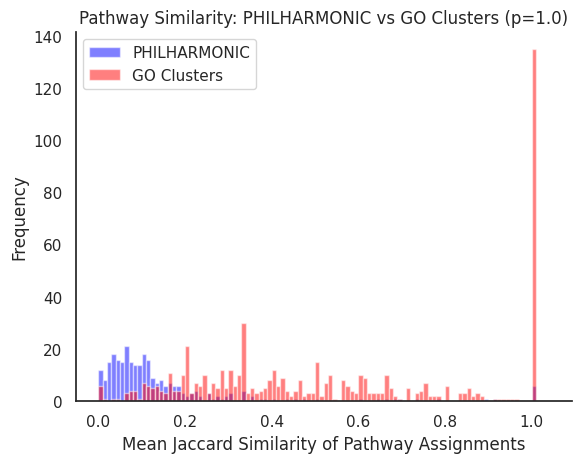

In [25]:
plt.hist(
    phil_mean,
    alpha=0.5,
    label="PHILHARMONIC",
    bins=np.arange(0, 1.05, 0.01),
    color="blue",
    ec="white",
)
plt.hist(
    go_mean,
    alpha=0.5,
    label="GO Clusters",
    bins=np.arange(0, 1.05, 0.01),
    color="red",
    ec="white",
)
plt.xlabel("Mean Jaccard Similarity of Pathway Assignments")
plt.ylabel("Frequency")
plt.title(f"Pathway Similarity: PHILHARMONIC vs GO Clusters (p={p_rand:.3})")
plt.legend()
sns.despine()

---
# Evalute network accuracy of function clusters

In [ ]:
# cluster_dict
# clusters_by_function
# full_G

In [71]:
phil_num_edges = []
phil_num_cc = []
func_num_edges = []
func_num_cc = []

for k, clust in cluster_dict.items():
    dscript_subgraph = full_G.subgraph(
        clust["members"] + list(clust["recipe"]["degree"]["0.75"])
    )
    num_edges = dscript_subgraph.number_of_edges()
    num_cc = nx.number_connected_components(dscript_subgraph)
    phil_num_edges.append(num_edges)
    phil_num_cc.append(num_cc)

for k, clust in clusters_by_function.items():
    dscript_subgraph = full_G.subgraph(clust["members"])
    num_edges = dscript_subgraph.number_of_edges()
    num_cc = nx.number_connected_components(dscript_subgraph)
    func_num_edges.append(num_edges)
    func_num_cc.append(num_cc)

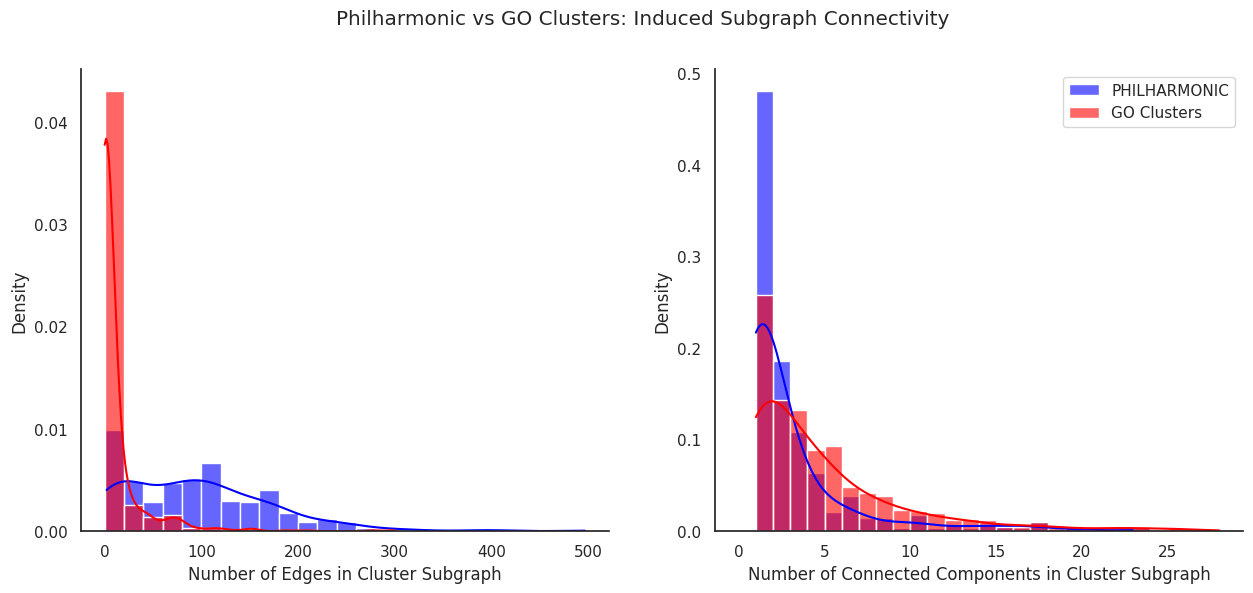

In [72]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

sns.histplot(
    phil_num_edges,
    label="PHILHARMONIC",
    alpha=0.6,
    bins=np.arange(0, max(phil_num_edges + func_num_edges) + 1, 20),
    color="blue",
    stat="density",
    kde=True,
    ax=ax[0],
)
sns.histplot(
    func_num_edges,
    label="GO Clusters",
    bins=np.arange(0, max(phil_num_edges + func_num_edges) + 1, 20),
    color="red",
    stat="density",
    alpha=0.6,
    kde=True,
    ax=ax[0],
)

sns.histplot(
    phil_num_cc,
    alpha=0.6,
    label="PHILHARMONIC",
    bins=np.arange(0, max(phil_num_cc + func_num_cc) + 1, 1),
    color="blue",
    ec="white",
    kde=True,
    stat="density",
    ax=ax[1],
)
sns.histplot(
    func_num_cc,
    alpha=0.6,
    label="GO Clusters",
    bins=np.arange(0, max(phil_num_cc + func_num_cc) + 1, 1),
    color="red",
    stat="density",
    ec="white",
    kde=True,
    ax=ax[1],
)
ax[0].set_xlabel("Number of Edges in Cluster Subgraph")
ax[1].set_xlabel("Number of Connected Components in Cluster Subgraph")
ax[0].set_ylabel("Density")
ax[1].set_ylabel("Density")
plt.suptitle("Philharmonic vs GO Clusters: Induced Subgraph Connectivity")
plt.legend()
sns.despine()
plt.show()

---